<a href="https://colab.research.google.com/github/Njdnatedawg/nathan_INFO4670_Fall2026/blob/main/INFO4670_HandsOn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INFO 4670 — Discussion 4 Hands-On Lab
## From Your Intuition to Real Code: Fraud Email Detection

---

> **Before running this notebook**, post your Discussion 4 response on Canvas first.  
> This lab lets you **verify your own logic** with real code and data.

## The Same Scenario — Now With Data

Your platform receives 1 million emails/day. About 5% are fraudulent.  
Three strategies emerged from the class:

| Strategy Type | What It Looks Like | Maps to Algorithm |
|---|---|---|
| "If domain is blacklisted, block" | Flat IF-THEN conditions | **Rule Set** |
| "First check domain, then urgency language..." | Branching hierarchy of questions | **Decision Tree** |
| "Each feature adds points to a fraud score" | Weighted probability calculation | **Naive Bayes** |

This notebook walks through all three using a dataset that mirrors Discussion 8 exactly.

**Estimated time: 45-60 minutes. Runs entirely in Google Colab — no setup needed.**


In [ ]:
# SETUP — Run this first!
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, ConfusionMatrixDisplay, precision_recall_curve
)
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Libraries loaded. Ready to catch fraudsters!')


Libraries loaded. Ready to catch fraudsters!


---
## Step 0 — Meet Your Dataset

We generate **500 emails** with features inspired directly by Discussion 8 posts:

| Feature | Description | Proposed by |
|---|---|---|
| `failed_auth` | SPF/DKIM/DMARC check failed | >15 students |
| `urgent_language` | "act now", "verify account" | Almost everyone |
| `suspicious_link` | URL mismatch or shortened link | Very common |
| `known_sender` | Sender has history on our platform | Several students |
| `bulk_send` | Sender sent 500+ emails this hour | Joseph Scott, Rohit Kukreja |

**Fraud rate: ~5%** — exactly like the Discussion 8 scenario.


Dataset: 500 emails
Fraud rate: 5.0%  <-- matches Discussion 8

Sample data (3 legitimate emails + 2 fraud emails):
--------------------------------------------------------------------------
  Row  failed_auth  urgent_language  suspicious_link  known_sender  bulk_send  fraud       
  --------------------------------------------------------------------------------------
  1    0            0                0                1             0          0  (legit)  
  2    0            0                0                1             0          0  (legit)  
  3    0            0                1                0             0          0  (legit)  
  4    1            0                1                0             1          1  <-- FRAUD  <<
  5    1            1                0                0             1          1  <-- FRAUD  <<

Rows 4-5 are fraud. Notice the pattern:
  failed_auth=1, suspicious_link=1, known_sender=0  -->  strong fraud signals
  known_sender=1, all flags=0            

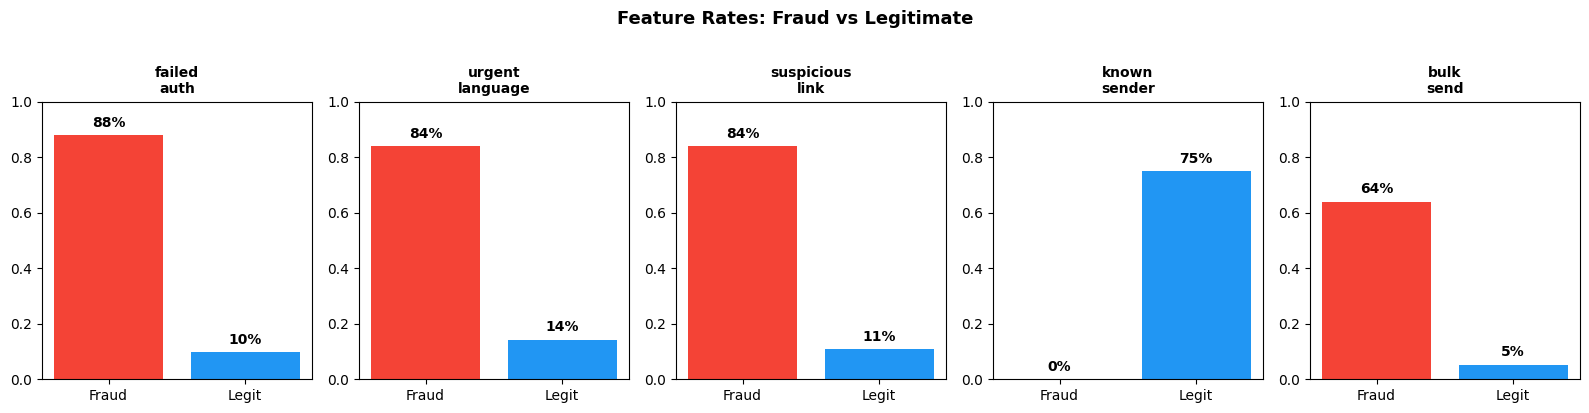

Which features are strongest signals for fraud?


In [ ]:
np.random.seed(42)
N = 500
n_fraud = 25
n_legit = N - n_fraud
feature_cols = ['failed_auth', 'urgent_language', 'suspicious_link', 'known_sender', 'bulk_send']

fraud_df = pd.DataFrame({
    'failed_auth':     np.random.binomial(1, 0.85, n_fraud),
    'urgent_language': np.random.binomial(1, 0.80, n_fraud),
    'suspicious_link': np.random.binomial(1, 0.90, n_fraud),
    'known_sender':    np.random.binomial(1, 0.05, n_fraud),
    'bulk_send':       np.random.binomial(1, 0.70, n_fraud),
    'fraud': 1
})
legit_df = pd.DataFrame({
    'failed_auth':     np.random.binomial(1, 0.08, n_legit),
    'urgent_language': np.random.binomial(1, 0.15, n_legit),
    'suspicious_link': np.random.binomial(1, 0.12, n_legit),
    'known_sender':    np.random.binomial(1, 0.75, n_legit),
    'bulk_send':       np.random.binomial(1, 0.05, n_legit),
    'fraud': 0
})
df = pd.concat([fraud_df, legit_df]).sample(frac=1, random_state=42).reset_index(drop=True)
print(f'Dataset: {len(df)} emails')
print(f'Fraud rate: {df["fraud"].mean():.1%}  <-- matches Discussion 8')


# ── Sample rows: 3 legitimate + 2 fraud, clearly labeled ─────────────────────
print()
print('Sample data (3 legitimate emails + 2 fraud emails):')
print('-' * 74)

legit_sample = df[df['fraud'] == 0].head(3)
fraud_sample = df[df['fraud'] == 1].head(2)
sample = pd.concat([legit_sample, fraud_sample]).reset_index(drop=True)
sample.index = range(1, 6)

# Format label column for readability
display = sample.copy()
display['fraud'] = display['fraud'].map({1: '1  <-- FRAUD', 0: '0  (legit)'})

col_widths = {c: max(len(c), display[c].astype(str).str.len().max()) for c in display.columns}
header = '  '.join(c.ljust(col_widths[c]) for c in display.columns)
print(f'  Row  {header}')
print('  ' + '-' * (sum(col_widths.values()) + 2 * len(col_widths)))
for idx, row in display.iterrows():
    line = '  '.join(str(row[c]).ljust(col_widths[c]) for c in display.columns)
    marker = '  <<' if '1' in str(row['fraud']) else ''
    print(f'  {idx}    {line}{marker}')

print()
print('Rows 4-5 are fraud. Notice the pattern:')
print('  failed_auth=1, suspicious_link=1, known_sender=0  -->  strong fraud signals')
print('  known_sender=1, all flags=0                       -->  typical legitimate email')

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, feat in enumerate(feature_cols):
    fr = df[df['fraud']==1][feat].mean()
    lr = df[df['fraud']==0][feat].mean()
    axes[i].bar(['Fraud','Legit'], [fr, lr], color=['#F44336','#2196F3'])
    axes[i].set_title(feat.replace('_','\n'), fontsize=10, fontweight='bold')
    axes[i].set_ylim(0, 1)
    for j, v in enumerate([fr, lr]):
        axes[i].text(j, v+0.03, f'{v:.0%}', ha='center', fontsize=10, fontweight='bold')
plt.suptitle('Feature Rates: Fraud vs Legitimate', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print('Which features are strongest signals for fraud?')


---
## Module 1 — The Accuracy Trap

### "Just predict everything as Legitimate — 95% accuracy!"

Many students correctly warned about this:

> *"Because fraud makes up such a small portion of total emails, the model may suffer a class imbalance."* — Taryn Glover

> *"Accuracy alone is not enough — track precision, recall, and the confusion matrix."* — Fiameta Hagos


  Baseline: Always Predict Legitimate
  Accuracy  : 95.0%   <-- Looks great! (it is not)
  Precision : 0.0%   <-- Useless
  Recall    : 0.0%   <-- Useless
  F1-Score  : 0.0%   <-- Useless

  This model catches ZERO fraud emails out of 25.
  Yet accuracy = 95%. This is the Accuracy Trap from Lecture 8.


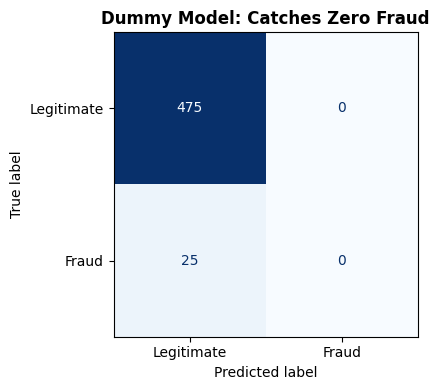

In [ ]:
y = df['fraud'].values
y_dummy = np.zeros(len(y), dtype=int)  # always predict Legitimate

print('=' * 50)
print('  Baseline: Always Predict Legitimate')
print('=' * 50)
print(f'  Accuracy  : {accuracy_score(y, y_dummy):.1%}   <-- Looks great! (it is not)')
print(f'  Precision : {precision_score(y, y_dummy, zero_division=0):.1%}   <-- Useless')
print(f'  Recall    : {recall_score(y, y_dummy, zero_division=0):.1%}   <-- Useless')
print(f'  F1-Score  : {f1_score(y, y_dummy, zero_division=0):.1%}   <-- Useless')
print()
print('  This model catches ZERO fraud emails out of 25.')
print('  Yet accuracy = 95%. This is the Accuracy Trap from Lecture 8.')

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y, y_dummy),
                       display_labels=['Legitimate','Fraud']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Dummy Model: Catches Zero Fraud', fontweight='bold')
plt.tight_layout()
plt.show()


### Reflection 1

**Q1.** The dummy model has 95% accuracy but is useless. What metric should you use instead when fraud is rare? Why?

*Your answer (double-click to edit):*
> ...

**Q2.** Several classmates said "False Negatives (missing fraud) are more dangerous than False Positives." Do you agree? What is the business trade-off?

*Your answer:*
> ...


---
## Module 2 — Rule Set: The IF-THEN Approach

Many students proposed hard filters as the first stage:

> *"Step 1: Rule set — emails with known malware hashes or blacklisted IPs are dropped immediately."* — Jacob Bartlett

> *"I would approach this as a flow chart: contains link yes/no, spelling errors yes/no."* — Shiara Holmes

A **Rule Set** is a flat list of IF-THEN conditions with no probability. Let's build it and measure.


Rule Set Results:
  Precision      : 55.8%
  Recall         : 96.0%
  F1-Score       : 70.6%
  False Positives: 19 legit emails blocked
  Fraud caught   : 24 / 25


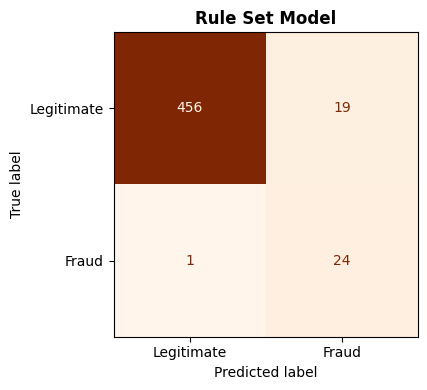

In [ ]:
def rule_set_classifier(row):
    # Rule 1: Failed auth AND suspicious link => block
    if row['failed_auth'] == 1 and row['suspicious_link'] == 1:
        return 1
    # Rule 2: Bulk sender AND unknown contact => block
    if row['bulk_send'] == 1 and row['known_sender'] == 0:
        return 1
    # Rule 3: Three red flags together
    if row['urgent_language'] == 1 and row['failed_auth'] == 1 and row['known_sender'] == 0:
        return 1
    return 0

df['rule_pred'] = df.apply(rule_set_classifier, axis=1)

print('Rule Set Results:')
print(f'  Precision      : {precision_score(y, df["rule_pred"]):.1%}')
print(f'  Recall         : {recall_score(y, df["rule_pred"]):.1%}')
print(f'  F1-Score       : {f1_score(y, df["rule_pred"]):.1%}')
print(f'  False Positives: {sum((df["rule_pred"]==1) & (y==0))} legit emails blocked')
print(f'  Fraud caught   : {sum((df["rule_pred"]==1) & (y==1))} / 25')

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y, df['rule_pred']),
                       display_labels=['Legitimate','Fraud']).plot(ax=ax, colorbar=False, cmap='Oranges')
ax.set_title('Rule Set Model', fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# YOUR TURN -- Modify the rules to match YOUR Discussion 8 logic!
# Goal: improve Recall (catch more fraud) without too many False Positives

def my_rule_set(row):
    # Edit this function to implement YOUR rules from Discussion 8.
    # Features: failed_auth, urgent_language, suspicious_link, known_sender, bulk_send
    # All values: 0 (absent) or 1 (present)

    # --- Your rules here ---
    if row['failed_auth'] == 1 and row['known_sender'] == 0:
        return 1
    # TODO: add more rules

    return 0

df['my_rule_pred'] = df.apply(my_rule_set, axis=1)

print('My Rule Set Results:')
print(f'  Precision      : {precision_score(y, df["my_rule_pred"]):.1%}')
print(f'  Recall         : {recall_score(y, df["my_rule_pred"]):.1%}')
print(f'  F1-Score       : {f1_score(y, df["my_rule_pred"]):.1%}')
print(f'  False Positives: {sum((df["my_rule_pred"]==1) & (y==0))} legit emails blocked')
print(f'  Fraud caught   : {sum((df["my_rule_pred"]==1) & (y==1))} / 25')


My Rule Set Results:
  Precision      : 61.1%
  Recall         : 88.0%
  F1-Score       : 72.1%
  False Positives: 14 legit emails blocked
  Fraud caught   : 22 / 25


### Reflection 2

**Q3.** Try to make your rule set catch all 25 fraud emails. What happens to your false positives? What is this trade-off called in Lecture 8?

*Your answer:*
> ...

**Q4.** What is the biggest weakness of a pure Rule Set? (What happens when scammers adapt their tactics?)

*Your answer:*
> ...


---
## Module 3 — Decision Tree: The Branching Hierarchy

Several students described a flowchart of sequential questions:

> *"First check authentication, then links, then sender history..."* — Kevin Ortega

> *"I would approach this as a flowchart."* — Seryna Payne, Dario Rocha-Perez

A Decision Tree **automates this ordering** using Information Gain. Let's see what question the algorithm picks first — and why.


Decision Tree (depth=3) Results:
  Precision : 58.3%
  Recall    : 100.0%
  F1-Score  : 73.7%


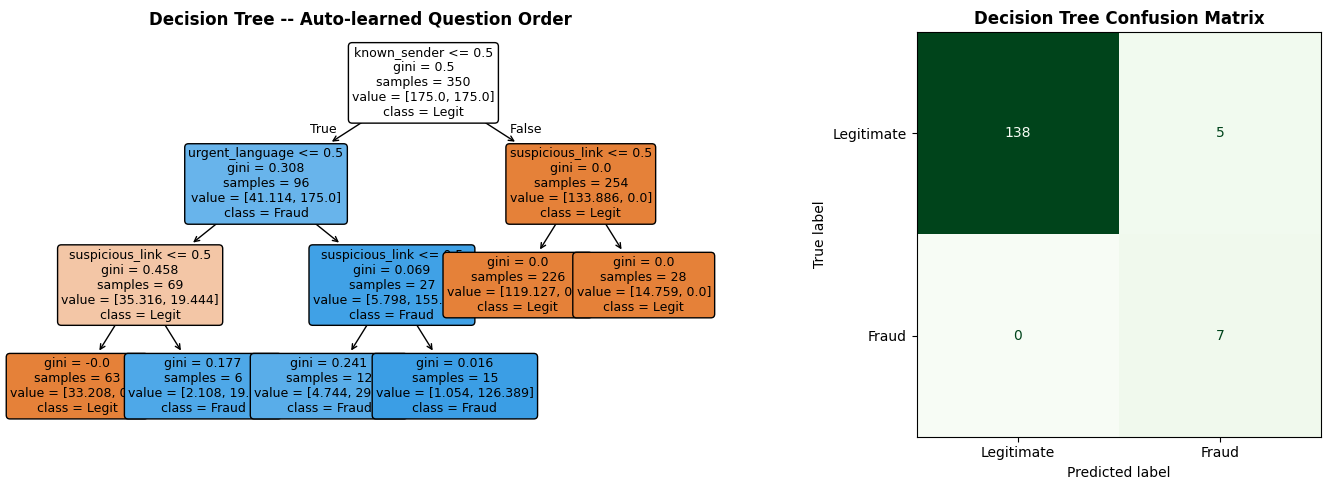


Text Rules:
|--- known_sender <= 0.50
|   |--- urgent_language <= 0.50
|   |   |--- suspicious_link <= 0.50
|   |   |   |--- class: 0
|   |   |--- suspicious_link >  0.50
|   |   |   |--- class: 1
|   |--- urgent_language >  0.50
|   |   |--- suspicious_link <= 0.50
|   |   |   |--- class: 1
|   |   |--- suspicious_link >  0.50
|   |   |   |--- class: 1
|--- known_sender >  0.50
|   |--- suspicious_link <= 0.50
|   |   |--- class: 0
|   |--- suspicious_link >  0.50
|   |   |--- class: 0



In [ ]:
X = df[feature_cols].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

dt = DecisionTreeClassifier(max_depth=3, random_state=42, class_weight='balanced')
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print('Decision Tree (depth=3) Results:')
print(f'  Precision : {precision_score(y_test, y_pred_dt):.1%}')
print(f'  Recall    : {recall_score(y_test, y_pred_dt):.1%}')
print(f'  F1-Score  : {f1_score(y_test, y_pred_dt):.1%}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_tree(dt, feature_names=feature_cols, class_names=['Legit','Fraud'],
          filled=True, rounded=True, fontsize=9, ax=axes[0])
axes[0].set_title('Decision Tree -- Auto-learned Question Order', fontweight='bold')
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_dt),
                       display_labels=['Legitimate','Fraud']).plot(
                       ax=axes[1], colorbar=False, cmap='Greens')
axes[1].set_title('Decision Tree Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

print('\nText Rules:')
print(export_text(dt, feature_names=feature_cols))


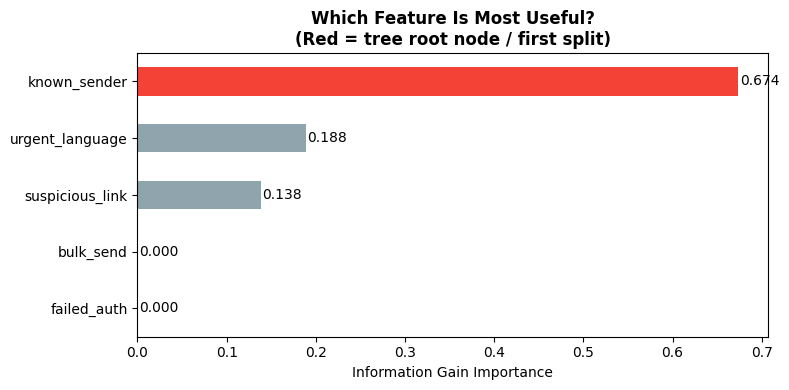


First question (root node): "known_sender"
This feature has the highest Information Gain -- reduces uncertainty the most.


In [ ]:
# Which feature does the tree pick FIRST?
importances = pd.Series(dt.feature_importances_, index=feature_cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
bar_colors = ['#F44336' if v == importances.max() else '#90A4AE' for v in importances]
importances.plot(kind='barh', ax=ax, color=bar_colors)
ax.set_xlabel('Information Gain Importance')
ax.set_title('Which Feature Is Most Useful?\n(Red = tree root node / first split)', fontweight='bold')
for i, v in enumerate(importances):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center')
plt.tight_layout()
plt.show()
print(f'\nFirst question (root node): "{importances.idxmax()}"')
print('This feature has the highest Information Gain -- reduces uncertainty the most.')


In [ ]:
# YOUR TURN -- Classify your own email!
# Change any value (0 or 1) and re-run to see the tree's decision

your_email = {
    'failed_auth':     0,   # SPF/DKIM failed?
    'urgent_language': 1,   # Contains urgent phrases?
    'suspicious_link': 0,   # Suspicious/shortened link?
    'known_sender':    0,   # Known sender with history?
    'bulk_send':       0,   # Sending to hundreds at once?
}

sample = np.array([[your_email[f] for f in feature_cols]])
pred   = dt.predict(sample)[0]
prob   = dt.predict_proba(sample)[0]

print('Email features:', your_email)
print(f'\nDecision Tree says: {"FRAUD" if pred == 1 else "Legitimate"}')
print(f'  P(Fraud) = {prob[1]:.1%}  |  P(Legit) = {prob[0]:.1%}')


Email features: {'failed_auth': 0, 'urgent_language': 1, 'suspicious_link': 0, 'known_sender': 0, 'bulk_send': 0}

Decision Tree says: FRAUD
  P(Fraud) = 86.0%  |  P(Legit) = 14.0%


### Reflection 3

**Q5.** Which feature did the tree split on first (root node)? Look at the Step 0 bar chart — does this make sense? Why does Information Gain choose this feature?

*Your answer:*
> ...

**Q6.** Read the text rules. Write the path to classifying a fraud email in plain English. Does it resemble Seryna Payne's or Dario Rocha-Perez's flowchart description?

*Your answer:*
> ...


---
## Module 4 — Naive Bayes: The Probability Calculation

The most popular approach in Discussion 8 was a **weighted scoring system**:

> *"Give each email a risk score. Suspicious link = +30, unknown sender = +20. If total > 70, it is fraud."* — Mason Rasberry

> *"I would use the Naive Bayes method to keep score."* — Melita Smith

This IS Naive Bayes. Let's calculate it by hand first (as in Lecture 8), then verify with sklearn.


In [ ]:
# Manual Naive Bayes: new email has failed_auth=1, urgent=1, link=0, known=0, bulk=0
train_df = pd.DataFrame(X_train, columns=feature_cols)
train_df['fraud'] = y_train
fraud_train = train_df[train_df['fraud'] == 1]
legit_train  = train_df[train_df['fraud'] == 0]

p_fraud = len(fraud_train) / len(train_df)
p_legit = len(legit_train) / len(train_df)
print('STEP 1 -- Prior Probabilities')
print(f'  P(fraud) = {len(fraud_train)}/{len(train_df)} = {p_fraud:.4f}')
print(f'  P(legit) = {len(legit_train)}/{len(train_df)} = {p_legit:.4f}')

new_email_vals = [1, 1, 0, 0, 0]
print('\nSTEP 2 -- Likelihoods [Laplace smoothing applied]')
print(f'{"Feature":<18} {"Val":>4}  {"P(|fraud)":>10}  {"P(|legit)":>10}')
print('-' * 50)

fraud_score = p_fraud
legit_score = p_legit
for feat, val in zip(feature_cols, new_email_vals):
    nf, nl = len(fraud_train), len(legit_train)
    if val == 1:
        pf = (fraud_train[feat].sum() + 1) / (nf + 2)
        pl = (legit_train[feat].sum() + 1) / (nl + 2)
    else:
        pf = (nf - fraud_train[feat].sum() + 1) / (nf + 2)
        pl = (nl - legit_train[feat].sum() + 1) / (nl + 2)
    print(f'  {feat:<16} {val:>4}    {pf:>10.4f}  {pl:>10.4f}')
    fraud_score *= pf
    legit_score *= pl

print('\nSTEP 3 -- Compare Posterior Scores')
print(f'  Fraud score = {fraud_score:.8f}')
print(f'  Legit score = {legit_score:.8f}')
print(f'  Prediction: {"FRAUD" if fraud_score > legit_score else "Legitimate"}')


STEP 1 -- Prior Probabilities
  P(fraud) = 18/350 = 0.0514
  P(legit) = 332/350 = 0.9486

STEP 2 -- Likelihoods [Laplace smoothing applied]
Feature             Val   P(|fraud)   P(|legit)
--------------------------------------------------
  failed_auth         1        0.8000      0.1018
  urgent_language     1        0.8500      0.1707
  suspicious_link     0        0.2000      0.8952
  known_sender        0        0.9500      0.2365
  bulk_send           0        0.4500      0.9521

STEP 3 -- Compare Posterior Scores
  Fraud score = 0.00299006
  Legit score = 0.00332213
  Prediction: Legitimate


In [ ]:
# Verify with sklearn, then simulate a sophisticated scammer
nb = BernoulliNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

print('sklearn Naive Bayes on test set:')
print(f'  Precision : {precision_score(y_test, y_pred_nb):.1%}')
print(f'  Recall    : {recall_score(y_test, y_pred_nb):.1%}')
print(f'  F1-Score  : {f1_score(y_test, y_pred_nb):.1%}')

print('\nSophisticated Scammer Simulation')
print('  (What Samuel Purkuti, Gavin Hecke, Jose Primo warned about)')
print('-' * 58)

scenarios = [
    ('Obvious scammer',            [1, 1, 1, 0, 1]),
    ('Hides bulk sending',         [1, 1, 1, 0, 0]),
    ('Avoids urgency language',    [1, 0, 1, 0, 0]),
    ('Spoofs legitimate domain',   [0, 1, 1, 0, 0]),
    ('Perfect disguise',           [0, 0, 0, 1, 0]),
]

print(f'{"Strategy":<30} {"P(Fraud)":>8}  Decision')
print('-' * 58)
for name, feats in scenarios:
    prob = nb.predict_proba([feats])[0][1]
    pred = nb.predict([feats])[0]
    status = 'CAUGHT' if pred == 1 else 'MISSED  <-- False Negative!'
    print(f'  {name:<28} {prob:>8.1%}  {status}')

print()
print('A scammer who hides all signals achieves P(Fraud) near 0.')
print('This is exactly the False Negative problem from Think-3.')


sklearn Naive Bayes on test set:
  Precision : 87.5%
  Recall    : 100.0%
  F1-Score  : 93.3%

Sophisticated Scammer Simulation
  (What Samuel Purkuti, Gavin Hecke, Jose Primo warned about)
----------------------------------------------------------
Strategy                       P(Fraud)  Decision
----------------------------------------------------------
  Obvious scammer                 99.9%  CAUGHT
  Hides bulk sending              96.9%  CAUGHT
  Avoids urgency language         52.8%  CAUGHT
  Spoofs legitimate domain        46.6%  MISSED  <-- False Negative!
  Perfect disguise                 0.0%  MISSED  <-- False Negative!

A scammer who hides all signals achieves P(Fraud) near 0.
This is exactly the False Negative problem from Think-3.


### Reflection 4

**Q7.** The "Perfect disguise" scammer evades detection. Fiameta Hagos and Samuel Purkuti predicted this failure. What two improvements would help catch this type of attacker?

*Your answer:*
> ...

**Q8.** Did your manual calculation match sklearn's output? Naive Bayes assumes all features are **independent**. Are `failed_auth` and `suspicious_link` truly independent in real emails? Does this matter for the final prediction?

*Your answer:*
> ...


---
## Module 5 — Head-to-Head: Which Strategy Wins?


                Precision  Recall  F1-Score  Accuracy
Model                                                
Rule Set            0.558    0.96     0.706     0.960
Decision Tree       0.556    1.00     0.714     0.960
Naive Bayes         0.923    0.96     0.941     0.994
Random Forest*      0.778    1.00     0.875     0.987

* Random Forest evaluated on held-out test set only


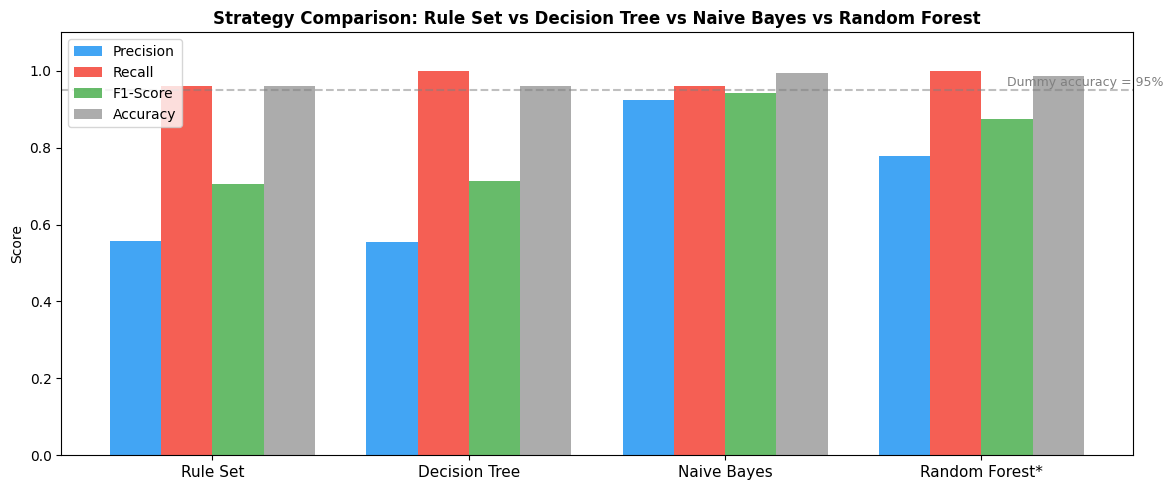

In [ ]:
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

results = []
for name, yt, yp in [
    ('Rule Set',        y,      df['rule_pred'].values),
    ('Decision Tree',   y,      dt.predict(X)),
    ('Naive Bayes',     y,      nb.predict(X)),
    ('Random Forest*', y_test, y_pred_rf),
]:
    results.append({
        'Model':     name,
        'Precision': precision_score(yt, yp, zero_division=0),
        'Recall':    recall_score(yt, yp, zero_division=0),
        'F1-Score':  f1_score(yt, yp, zero_division=0),
        'Accuracy':  accuracy_score(yt, yp),
    })

res_df = pd.DataFrame(results).set_index('Model')
print(res_df.round(3).to_string())
print('\n* Random Forest evaluated on held-out test set only')

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(res_df))
w = 0.2
for i, (col, color) in enumerate([
    ('Precision','#2196F3'), ('Recall','#F44336'), ('F1-Score','#4CAF50'), ('Accuracy','#9E9E9E')
]):
    ax.bar(x + i*w, res_df[col], w, label=col, color=color, alpha=0.85)
ax.set_xticks(x + 1.5*w)
ax.set_xticklabels(res_df.index, fontsize=11)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Strategy Comparison: Rule Set vs Decision Tree vs Naive Bayes vs Random Forest',
             fontweight='bold')
ax.legend()
ax.axhline(0.95, color='gray', linestyle='--', alpha=0.5)
ax.text(3.4, 0.96, 'Dummy accuracy = 95%', fontsize=9, color='gray')
plt.tight_layout()
plt.show()


---
## BONUS — The Precision-Recall Trade-off

Every student who set a threshold ("score > 70 -> fraud") was choosing a point on this curve.


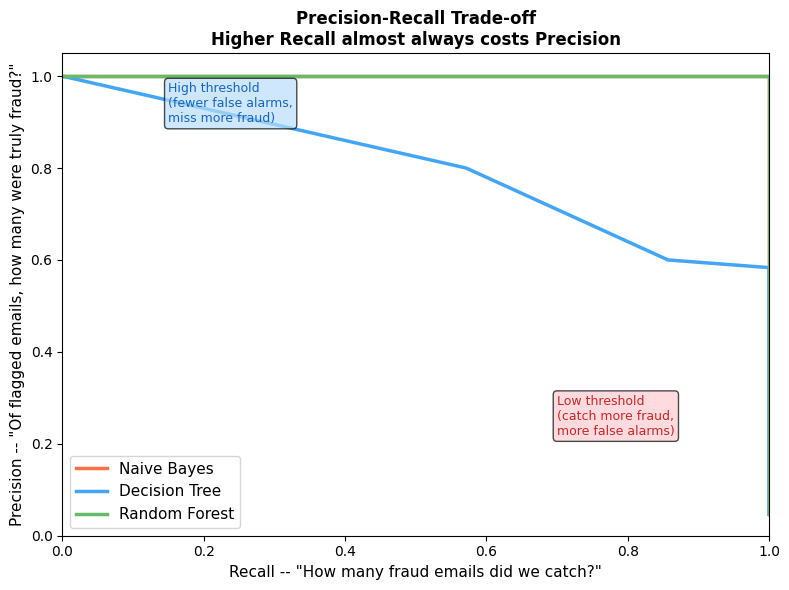

Students proposed thresholds like 70, 80, 0.85 -- each is a different point on this curve.
There is no free lunch: you must choose what to optimize for.


In [ ]:
nb_probs = nb.predict_proba(X_test)[:, 1]
dt_probs = dt.predict_proba(X_test)[:, 1]
rf_probs = rf.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
for probs, name, color in [
    (nb_probs, 'Naive Bayes',   '#FF7043'),
    (dt_probs, 'Decision Tree', '#42A5F5'),
    (rf_probs, 'Random Forest', '#66BB6A'),
]:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    ax.plot(rec, prec, label=name, color=color, linewidth=2.5)

ax.set_xlabel('Recall -- "How many fraud emails did we catch?"', fontsize=11)
ax.set_ylabel('Precision -- "Of flagged emails, how many were truly fraud?"', fontsize=11)
ax.set_title('Precision-Recall Trade-off\nHigher Recall almost always costs Precision',
             fontweight='bold', fontsize=12)
ax.legend(fontsize=11)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.annotate('High threshold\n(fewer false alarms,\nmiss more fraud)',
            xy=(0.15, 0.90), fontsize=9, color='#1565C0',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#BBDEFB', alpha=0.7))
ax.annotate('Low threshold\n(catch more fraud,\nmore false alarms)',
            xy=(0.70, 0.22), fontsize=9, color='#C62828',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFCDD2', alpha=0.7))
plt.tight_layout()
plt.show()

print('Students proposed thresholds like 70, 80, 0.85 -- each is a different point on this curve.')
print('There is no free lunch: you must choose what to optimize for.')


---
## Summary

| What You Proposed in Discussion 4 | Algorithm | Strength | Weakness |
|---|---|---|---|
| "Hard IF-THEN filters" | Rule Set | Fast, transparent | Fragile when scammers adapt |
| "Flowchart of questions" | Decision Tree | Auto-learns best order | Can overfit |
| "Weighted scoring system" | Naive Bayes | Probabilistic, handles uncertainty | Assumes independence |
| "ML model" (many students) | Random Forest | Robust, handles imbalance | Less interpretable |

**Core insight from Lecture 8:** At 5% fraud rate, accuracy is meaningless.  
You need **Recall** (catch fraud) and **Precision** (protect real customers) — they always trade off.

---

### Checklist Before Leaving
- [ ] Ran all cells and read the outputs
- [ ] Answered Q1-Q10 in the Reflection cells
- [ ] Modified the rule set (Module 2) and tested your own email (Module 3)
- [ ] Can explain why your Discussion 8 logic maps to a specific algorithm
- [ ] Wrote a peer reply draft in Q10 ready to post on Canvas
